# 03 | Underwater Image Enhancement: CLAHE and FUnIE-GAN
**Evaluating Underwater Image Enhancement for CNN-Based Robotic Segmentation**  

**Research question.** How do conventional contrast enhancement and a pretrained generative model alter underwater imagery before fixed-model semantic segmentation?

I use the **locked SUIM manifest** from Notebook 01 and the frozen U-Net established in Notebook 02. This notebook does **not** train or evaluate the U-Net. It creates reproducible enhanced images and assesses visual/image-quality changes. The **official test set is not used to choose parameters or models**; it is processed only after enhancement settings have been locked. Findings about segmentation effects belong exclusively to Notebook 04.



## 1. Introduction and research objectives

Underwater imagery often exhibits nonuniform illumination, color attenuation, reduced contrast, and suspended-particle interference. I compare **CLAHE**, a deterministic local contrast transformation, with **FUnIE-GAN**, a pretrained image-to-image enhancement generator. The goal is to characterize image changes while maintaining image identity, spatial resolution, and segmentation ground truth. I examine paired changes in image statistics, processing costs, and the appearance of annotated plant and robot regions.

**Scope boundary:** Better-looking images do not necessarily yield better segmentation. No segmentation improvements are claimed in this notebook.

## 2. Experimental environment and reproducibility

I restore the same SUIM project and reviewed source modules used in Notebook 02. All Python imports appear in the following setup cell. I fix random seeds, record package versions, and store outputs in the existing research Drive folder. I do not modify the locked manifest or original masks.

In [1]:
import os
import sys
import json
import time
import random
import hashlib
import shutil
import zipfile
import subprocess
import platform
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import torch
from PIL import Image
from IPython.display import display
from google.colab import drive

drive.mount('/content/drive')
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DRIVE_ROOT = Path('/content/drive/MyDrive/Underwater_Research')
PROJECT = Path('/content/suim_project')
SOURCE = PROJECT / 'src'
MANIFEST = PROJECT / 'results/tables/notebook_01/manifest.csv'
RESULTS = DRIVE_ROOT / 'results'
ENHANCED = RESULTS / 'enhanced'
TABLES = RESULTS / 'tables/notebook_03'
FIGURES = RESULTS / 'figures/notebook_03'
MODEL_DIR = DRIVE_ROOT / 'pretrained_models/funie_gan'
for folder in [TABLES, FIGURES, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

archive_path = DRIVE_ROOT / 'underwater-robotic-segmentation.zip'
assert archive_path.is_file(), 'Missing project archive in Underwater_Research.'
assert (DRIVE_ROOT / 'manifest.csv').is_file(), 'Missing locked manifest.csv.'
assert (DRIVE_ROOT / 'exclusions.csv').is_file(), 'Missing exclusions.csv.'
if not (SOURCE / 'dataset.py').is_file() or not (PROJECT / 'data/SUIM').is_dir():
    with zipfile.ZipFile(archive_path) as archive:
        matches = [m.filename for m in archive.infolist() if m.filename.endswith('src/train.py')]
        assert len(matches) == 1, 'Cannot identify source directory in archive.'
        prefix = matches[0][:-len('src/train.py')]
        for member in archive.infolist():
            if member.is_dir() or not member.filename.startswith(prefix):
                continue
            relative = Path(member.filename[len(prefix):])
            if not relative.parts or relative.is_absolute() or '..' in relative.parts:
                continue
            if relative.parts[0] not in {'src', 'data'}:
                continue
            destination = PROJECT / relative
            destination.parent.mkdir(parents=True, exist_ok=True)
            with archive.open(member) as src, destination.open('wb') as dst:
                shutil.copyfileobj(src, dst)
SOURCE.mkdir(parents=True, exist_ok=True)
for filename in ['common.py', 'dataset.py', 'unet.py', 'train.py', 'build_manifest.py']:
    path = DRIVE_ROOT / 'source_review' / filename
    assert path.is_file(), f'Missing reviewed source: {filename}'
    shutil.copy2(path, SOURCE / filename)
MANIFEST.parent.mkdir(parents=True, exist_ok=True)
for filename in ['manifest.csv', 'exclusions.csv']:
    shutil.copy2(DRIVE_ROOT / filename, MANIFEST.parent / filename)
os.chdir(PROJECT)
if str(SOURCE) not in sys.path:
    sys.path.insert(0, str(SOURCE))
from dataset import SuimDataset
from common import CLASS_NAMES, NUM_CLASSES

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
sns.set_theme(style='whitegrid', context='notebook', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180})
print('Device:', DEVICE, '| GPU:', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'None')
print('Python:', platform.python_version(), '| PyTorch:', torch.__version__, '| OpenCV:', cv2.__version__)
print('Research root:', DRIVE_ROOT)

Mounted at /content/drive
Device: cuda | GPU: Tesla T4
Python: 3.13.16 | PyTorch: 2.14.1+cu130 | OpenCV: 4.14.0
Research root: /content/drive/MyDrive/Underwater_Research


## 3. Dataset integrity and experimental controls

I verify the **1,204 training / 214 validation / 110 test** split and the locked manifest checksum. The original segmentation masks are never enhanced, resampled, or overwritten. Images are loaded through the same non-augmented `SuimDataset` representation as Notebook 02, so their 256 × 256 RGB geometry matches the segmentation baseline. For each enhanced output I retain its original split and image stem.

In [2]:
df = pd.read_csv(MANIFEST)
assert {'split', 'stem'}.issubset(df.columns)
assert df['stem'].is_unique
assert df['split'].value_counts().to_dict() == {'train': 1204, 'val': 214, 'test': 110}
manifest_sha = hashlib.sha256(MANIFEST.read_bytes()).hexdigest()
EXPECTED_MANIFEST_SHA = '30713993fb9fbd669bee764758ccd3c2fd83cf9af953295c0940e5ccdca97b69'
assert manifest_sha == EXPECTED_MANIFEST_SHA, f'Manifest checksum changed: {manifest_sha}'
assert len(pd.read_csv(MANIFEST.parent / 'exclusions.csv')) == 107
DATASETS = {split: SuimDataset(split, manifest=MANIFEST, augment=False) for split in ['train','val','test']}
for split, ds in DATASETS.items():
    assert len(ds) == {'train':1204,'val':214,'test':110}[split]
    x, y = ds[0]
    assert x.shape == (3,256,256) and y.shape == (256,256)
print('Locked manifest SHA256:', manifest_sha)
display(df['split'].value_counts().rename_axis('split').reset_index(name='images'))

def raw_rgb(split, index):
    tensor, _ = DATASETS[split][index]
    return np.uint8(np.round(np.clip((tensor.permute(1,2,0).numpy() + 1) * 127.5, 0, 255)))

def get_mask(split, index):
    return DATASETS[split][index][1].numpy()

def image_stem(split, index):
    return str(df.loc[df['split'] == split, 'stem'].iloc[index])

assert len({image_stem('val', i) for i in range(len(DATASETS['val']))}) == 214
print('Dataset and mask integrity checks passed.')

Locked manifest SHA256: 30713993fb9fbd669bee764758ccd3c2fd83cf9af953295c0940e5ccdca97b69


,split,images
0,train,1204
1,val,214
2,test,110


Dataset and mask integrity checks passed.


## 4. RAW image baseline

I inspect unmodified validation images before enhancement. These examples provide a visual reference for color cast, contrast, illumination, and object visibility. The images are displayed in RGB and are not used to estimate segmentation accuracy.

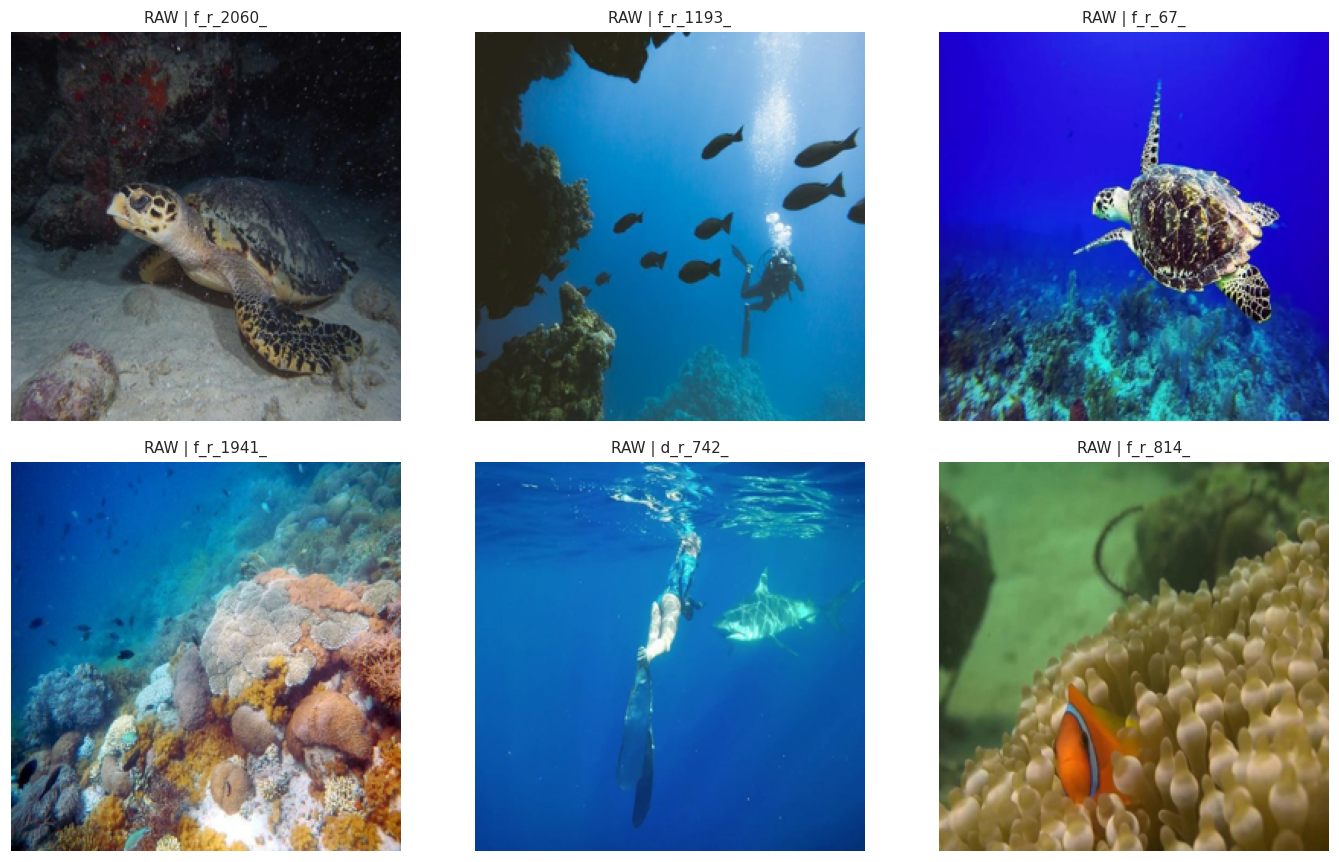

In [3]:
preview_indices = np.linspace(0, len(DATASETS['val'])-1, 6, dtype=int)
fig, axes = plt.subplots(2,3,figsize=(13,8))
for ax, idx in zip(axes.flat, preview_indices):
    ax.imshow(raw_rgb('val', int(idx)))
    ax.set_title(f'RAW | {image_stem("val", int(idx))}', fontsize=10)
    ax.axis('off')
plt.tight_layout()
fig.savefig(FIGURES/'raw_validation_examples.png', bbox_inches='tight')
plt.show()

## 5. CLAHE implementation

I apply CLAHE to the **L channel in LAB color space**, preserving the original chromatic channels as far as the color-space conversion permits. This avoids applying CLAHE independently to R, G, and B, which can introduce strong color artifacts. I document `clipLimit` and tile-grid size and hold these values fixed for all subsequent images.

In [4]:
CLAHE_CANDIDATES = [
    {'clip_limit': 1.5, 'tile_grid': 8},
    {'clip_limit': 2.0, 'tile_grid': 8},
    {'clip_limit': 3.0, 'tile_grid': 8},
]

def apply_clahe(rgb, clip_limit=2.0, tile_grid=8):
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    enhanced_l = cv2.createCLAHE(clipLimit=float(clip_limit), tileGridSize=(int(tile_grid), int(tile_grid))).apply(l)
    return cv2.cvtColor(cv2.merge((enhanced_l, a, b)), cv2.COLOR_LAB2RGB)

sample = raw_rgb('val', int(preview_indices[0]))
assert apply_clahe(sample).shape == sample.shape
print('CLAHE candidate settings:', CLAHE_CANDIDATES)

CLAHE candidate settings: [{'clip_limit': 1.5, 'tile_grid': 8}, {'clip_limit': 2.0, 'tile_grid': 8}, {'clip_limit': 3.0, 'tile_grid': 8}]


## 6. FUnIE-GAN model setup and checkpoint verification

I use the **authors' PyTorch implementation** (`xahidbuffon/FUnIE-GAN`, `PyTorch/nets/funiegan.py`) and its 256 × 256, `[-1,1]` RGB input/output convention. I record the repository commit and SHA256 of the actual checkpoint. The model must load **strictly** into `GeneratorFunieGAN`; incompatible, missing, or randomly initialized weights are not accepted.

**Checkpoint requirement:** The official PyTorch example references `PyTorch/models/funie_generator.pth`. The notebook first checks for this file in the cloned official repository and in the persistent Drive model folder. If neither contains a valid checkpoint, upload a verified pretrained `funie_generator.pth` to `Underwater_Research/pretrained_models/funie_gan/` and rerun this cell. A missing checkpoint is a blocking dependency, **not** a reason to train on SUIM or silently switch models.

Sources: [FUnIE-GAN official project](https://github.com/xahidbuffon/FUnIE-GAN), [authors' PyTorch test script](https://github.com/xahidbuffon/FUnIE-GAN/blob/master/PyTorch/test.py).

In [5]:
OFFICIAL_REPO = 'https://github.com/xahidbuffon/FUnIE-GAN.git'
REPO_DIR = Path('/content/FUnIE-GAN')
if not (REPO_DIR / 'PyTorch/nets/funiegan.py').is_file():
    subprocess.run(['git','clone','--depth','1',OFFICIAL_REPO,str(REPO_DIR)],check=True)
repo_commit = subprocess.check_output(['git','-C',str(REPO_DIR),'rev-parse','HEAD'], text=True).strip()
if str(REPO_DIR/'PyTorch') not in sys.path:
    sys.path.insert(0, str(REPO_DIR/'PyTorch'))
from nets.funiegan import GeneratorFunieGAN

checkpoint_candidates = [MODEL_DIR/'funie_generator.pth', REPO_DIR/'PyTorch/models/funie_generator.pth']
existing = [p for p in checkpoint_candidates if p.is_file() and p.stat().st_size > 100_000]
assert existing, ('No pretrained FUnIE-GAN checkpoint found. Place a verified funie_generator.pth in '
                  f'{MODEL_DIR} and rerun. Do not use random weights.')
FUNIE_CHECKPOINT = existing[0]
weights = torch.load(FUNIE_CHECKPOINT, map_location='cpu', weights_only=True)
if isinstance(weights, dict) and 'state_dict' in weights:
    weights = weights['state_dict']
assert isinstance(weights, dict) and weights, 'Invalid checkpoint state dictionary.'
if all(str(k).startswith('module.') for k in weights):
    weights = {k[len('module.'):]: v for k,v in weights.items()}
funie_model = GeneratorFunieGAN().to(DEVICE)
funie_model.load_state_dict(weights, strict=True)
funie_model.eval()
for parameter in funie_model.parameters():
    parameter.requires_grad_(False)
funie_sha = hashlib.sha256(FUNIE_CHECKPOINT.read_bytes()).hexdigest()
with torch.inference_mode():
    sanity = funie_model(torch.zeros(1,3,256,256,device=DEVICE))
assert sanity.shape == (1,3,256,256) and torch.isfinite(sanity).all()
print('Official repository commit:', repo_commit)
print('Checkpoint:', FUNIE_CHECKPOINT)
print('Checkpoint SHA256:', funie_sha)
print('Strict pretrained checkpoint loading: PASSED')

def apply_funie(rgb):
    x = torch.from_numpy(np.ascontiguousarray(rgb.transpose(2,0,1))).float().unsqueeze(0).to(DEVICE)
    x = x / 127.5 - 1.0
    with torch.inference_mode():
        y = funie_model(x).squeeze(0).cpu().permute(1,2,0).numpy()
    return np.uint8(np.round(np.clip((y + 1.0) * 127.5, 0, 255)))

Official repository commit: 8f934c834c94e007b00866186b9ee624dc2b7b69
Checkpoint: /content/FUnIE-GAN/PyTorch/models/funie_generator.pth
Checkpoint SHA256: e4fcb50e03868f1683c244b1c125def30df335ec43d9bb001b8700c03b8f2bd6
Strict pretrained checkpoint loading: PASSED


## 7. Enhancement parameter selection and method lock

I compare a small, predefined CLAHE candidate set on **validation images only** and inspect its effect on image appearance and clipping. I select the moderate default (`clipLimit=2.0`, `tileGridSize=8`) as a fixed methodological setting, not by optimizing segmentation results. The pretrained FUnIE-GAN checkpoint and preprocessing are fixed. **No official test images or U-Net scores inform these choices.**

In [6]:
selection_indices = np.linspace(0, len(DATASETS['val'])-1, 4, dtype=int)
fig, axes = plt.subplots(len(selection_indices), 1+len(CLAHE_CANDIDATES), figsize=(16,12))
for row, idx in enumerate(selection_indices):
    rgb = raw_rgb('val',int(idx))
    axes[row,0].imshow(rgb)
    axes[row,0].set_title('RAW')
    for j, config in enumerate(CLAHE_CANDIDATES, start=1):
        axes[row,j].imshow(apply_clahe(rgb, **config))
        axes[row,j].set_title(f"CLAHE clip={config['clip_limit']}")
    for ax in axes[row]:
        ax.axis('off')
plt.tight_layout()
fig.savefig(FIGURES/'clahe_parameter_review.png',bbox_inches='tight')
plt.show()
CLAHE_CONFIG = {'clip_limit':2.0,'tile_grid':8}
LOCKED_CONFIG = {
    'manifest_sha256':manifest_sha,
    'seed':SEED,
    'image_size':[256,256],
    'clahe':CLAHE_CONFIG,
    'funie':{'repository':OFFICIAL_REPO,'commit':repo_commit,'checkpoint_sha256':funie_sha,
             'normalization':'RGB [0,255] -> [-1,1] -> [0,255]'},
    'selection_policy':'No test-set tuning; no U-Net segmentation feedback'
}
config_file = TABLES/'enhancement_config.json'
if config_file.exists():
    previous = json.loads(config_file.read_text())
    assert previous == LOCKED_CONFIG, 'A different configuration is already locked; investigate before overwriting.'
else:
    config_file.write_text(json.dumps(LOCKED_CONFIG,indent=2))
print('Enhancement configuration locked:', config_file)

Output hidden; open in https://colab.research.google.com to view.

## 8. Enhancement pipeline and image generation

I process **validation images first**, then apply the already locked configuration to the **official test images**. I save lossless PNG files using the original manifest stems. Each output has the same 256 × 256 geometry and split as its RAW counterpart. Outputs are persistent in Google Drive, and existing files are verified rather than silently overwritten. The original masks are never modified.

In [7]:
def synchronize_gpu():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()

def generate_split(split):
    assert split in {'val','test'}
    assert json.loads(config_file.read_text()) == LOCKED_CONFIG
    records = []
    for i in range(len(DATASETS[split])):
        stem = image_stem(split,i)
        raw = raw_rgb(split,i)
        for method, function in [('clahe',lambda im:apply_clahe(im,**CLAHE_CONFIG)),
                                 ('funie_gan',apply_funie)]:
            folder = ENHANCED/method/split
            folder.mkdir(parents=True,exist_ok=True)
            output_path = folder/f'{stem}.png'
            synchronize_gpu()
            start = time.perf_counter()
            enhanced = function(raw)
            synchronize_gpu()
            latency_ms = (time.perf_counter()-start)*1000
            assert enhanced.shape == raw.shape and enhanced.dtype == np.uint8
            if output_path.exists():
                with Image.open(output_path) as previous:
                    assert np.array_equal(np.asarray(previous.convert('RGB')),enhanced), f'Existing output differs: {output_path}'
            else:
                Image.fromarray(enhanced,'RGB').save(output_path)
            records.append({'split':split,'stem':stem,'method':method,'output_path':str(output_path),
                            'height':256,'width':256,'processing_ms':latency_ms,
                            'sha256':hashlib.sha256(output_path.read_bytes()).hexdigest()})
        if (i+1)%40 == 0 or i+1 == len(DATASETS[split]):
            print(f'{split}: {i+1}/{len(DATASETS[split])} images processed')
    return pd.DataFrame(records)

val_outputs = generate_split('val')
assert len(val_outputs) == 428
print('Validation enhancements complete. Locked configuration remains unchanged.')

/tmp/ipykernel_498/3498677958.py:27: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(enhanced,'RGB').save(output_path)


val: 40/214 images processed
val: 80/214 images processed
val: 120/214 images processed
val: 160/214 images processed
val: 200/214 images processed
val: 214/214 images processed
Validation enhancements complete. Locked configuration remains unchanged.


## 9. Qualitative RAW / CLAHE / FUnIE-GAN comparison

I inspect paired outputs for the **same validation images**. This avoids misleading comparisons between different scenes. I examine color cast, brightness, contrast, visibility of structural boundaries, and unnatural artifacts. Visual appeal is not treated as evidence of improved segmentation.

In [8]:
def load_enhanced(split, index, method):
    path = ENHANCED/method/split/f'{image_stem(split,index)}.png'
    with Image.open(path) as im:
        return np.asarray(im.convert('RGB')).copy()

fig, axes = plt.subplots(4,3,figsize=(14,14))
for row, idx in enumerate(selection_indices):
    idx = int(idx)
    images = [raw_rgb('val',idx),load_enhanced('val',idx,'clahe'),load_enhanced('val',idx,'funie_gan')]
    for col, image in enumerate(images):
        axes[row,col].imshow(image)
        axes[row,col].axis('off')
        if row == 0:
            axes[row,col].set_title(['RAW','CLAHE','FUnIE-GAN'][col],fontweight='bold')
plt.tight_layout()
fig.savefig(FIGURES/'qualitative_comparison.png',bbox_inches='tight')
plt.show()

Output hidden; open in https://colab.research.google.com to view.

## 10. Quantitative image-quality analysis

Without paired clean reference images, I use **descriptive no-reference statistics**, not ground-truth restoration accuracy. These include luminance mean and standard deviation, grayscale gradient magnitude, saturation, and clipping fraction. I calculate each statistic on the **same image under all three conditions** and compare paired distributions. Larger contrast or gradient magnitude is not automatically better; enhancement can also amplify noise or create artifacts. I do **not** label SSIM/PSNR relative to RAW as restoration quality.

Image-quality measurements: 642
Unique validation images: 214
Methods: RAW, CLAHE, FUnIE-GAN

Image-Quality Summary Statistics


luminance_mean                  luminance_std                  \
                    mean     std   median          mean     std  median   
RAW              108.676  27.731  107.793        43.684  12.894  44.851   
CLAHE            119.571  20.748  120.650        52.142  12.538  54.380   
FUnIE-GAN        106.470  28.327  105.055        44.596  12.487  45.477   

          saturation_mean                  gradient_mean                   \
                     mean     std   median          mean     std   median   
RAW               145.407  51.434  139.600        61.175  33.046   58.210   
CLAHE             132.652  44.804  130.159       110.954  50.279  108.195   
FUnIE-GAN         125.361  42.959  121.095        68.688  33.164   66.196   

          clipped_fraction                
                      mean    std median  
RAW                  0.038  0.067  0.009  
CLAHE                0.040  0.048  0.024  
FUnIE-GAN            0.005  0.025  0.000

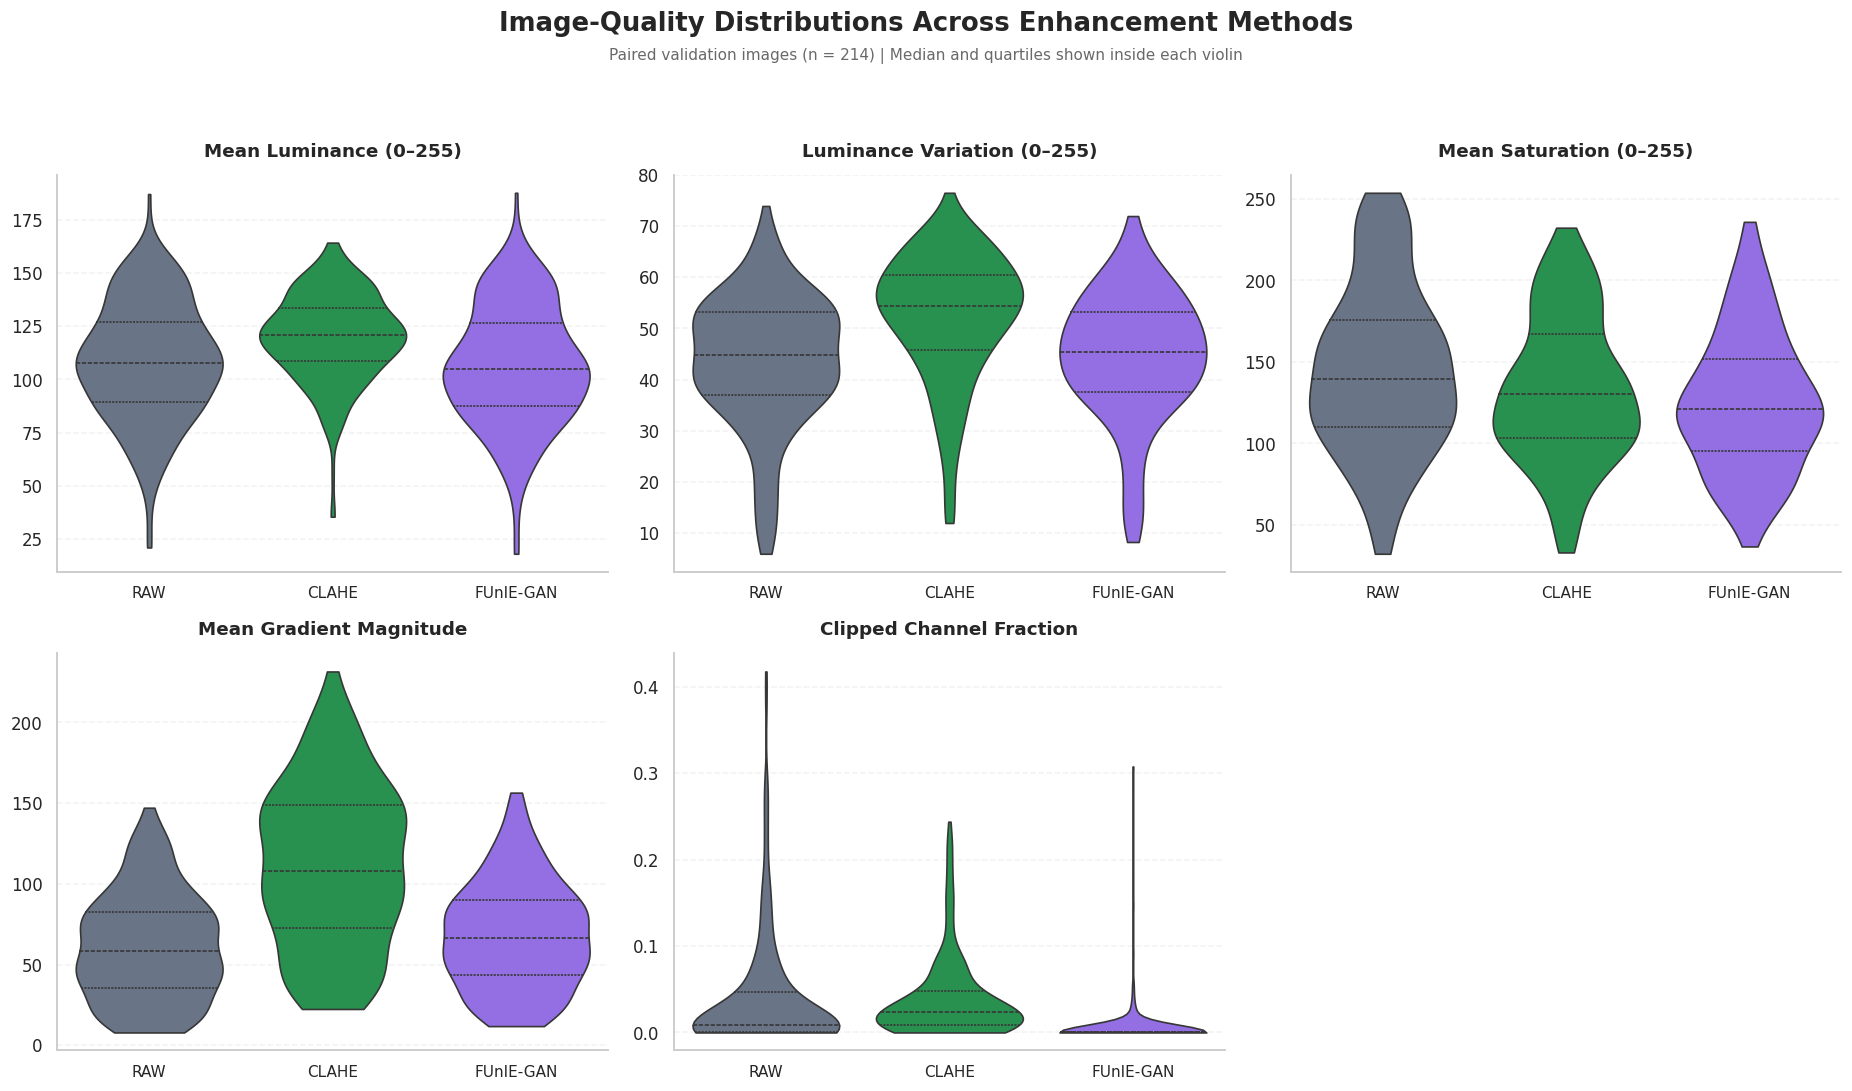


Paired Image-Quality Changes Relative to RAW


,metric,method,mean_change,median_change,std_change,positive_fraction
0,luminance_mean,clahe,10.8943,11.0270,9.9385,0.8738
1,luminance_mean,funie_gan,-2.2061,-2.5997,3.7684,0.2196
2,luminance_std,clahe,8.4576,8.3281,5.2416,0.9439
3,luminance_std,funie_gan,0.9121,0.6373,2.8865,0.5981
4,saturation_mean,clahe,-12.7543,-11.9964,15.8853,0.1822
5,saturation_mean,funie_gan,-20.0462,-20.8728,40.8173,0.3411
6,gradient_mean,clahe,49.7793,51.0109,19.4317,1.0000
7,gradient_mean,funie_gan,7.5135,6.9743,5.3664,0.9393
8,clipped_fraction,clahe,0.0013,0.0056,0.0650,0.6729
9,clipped_fraction,funie_gan,-0.0338,-0.0059,0.0649,0.0467


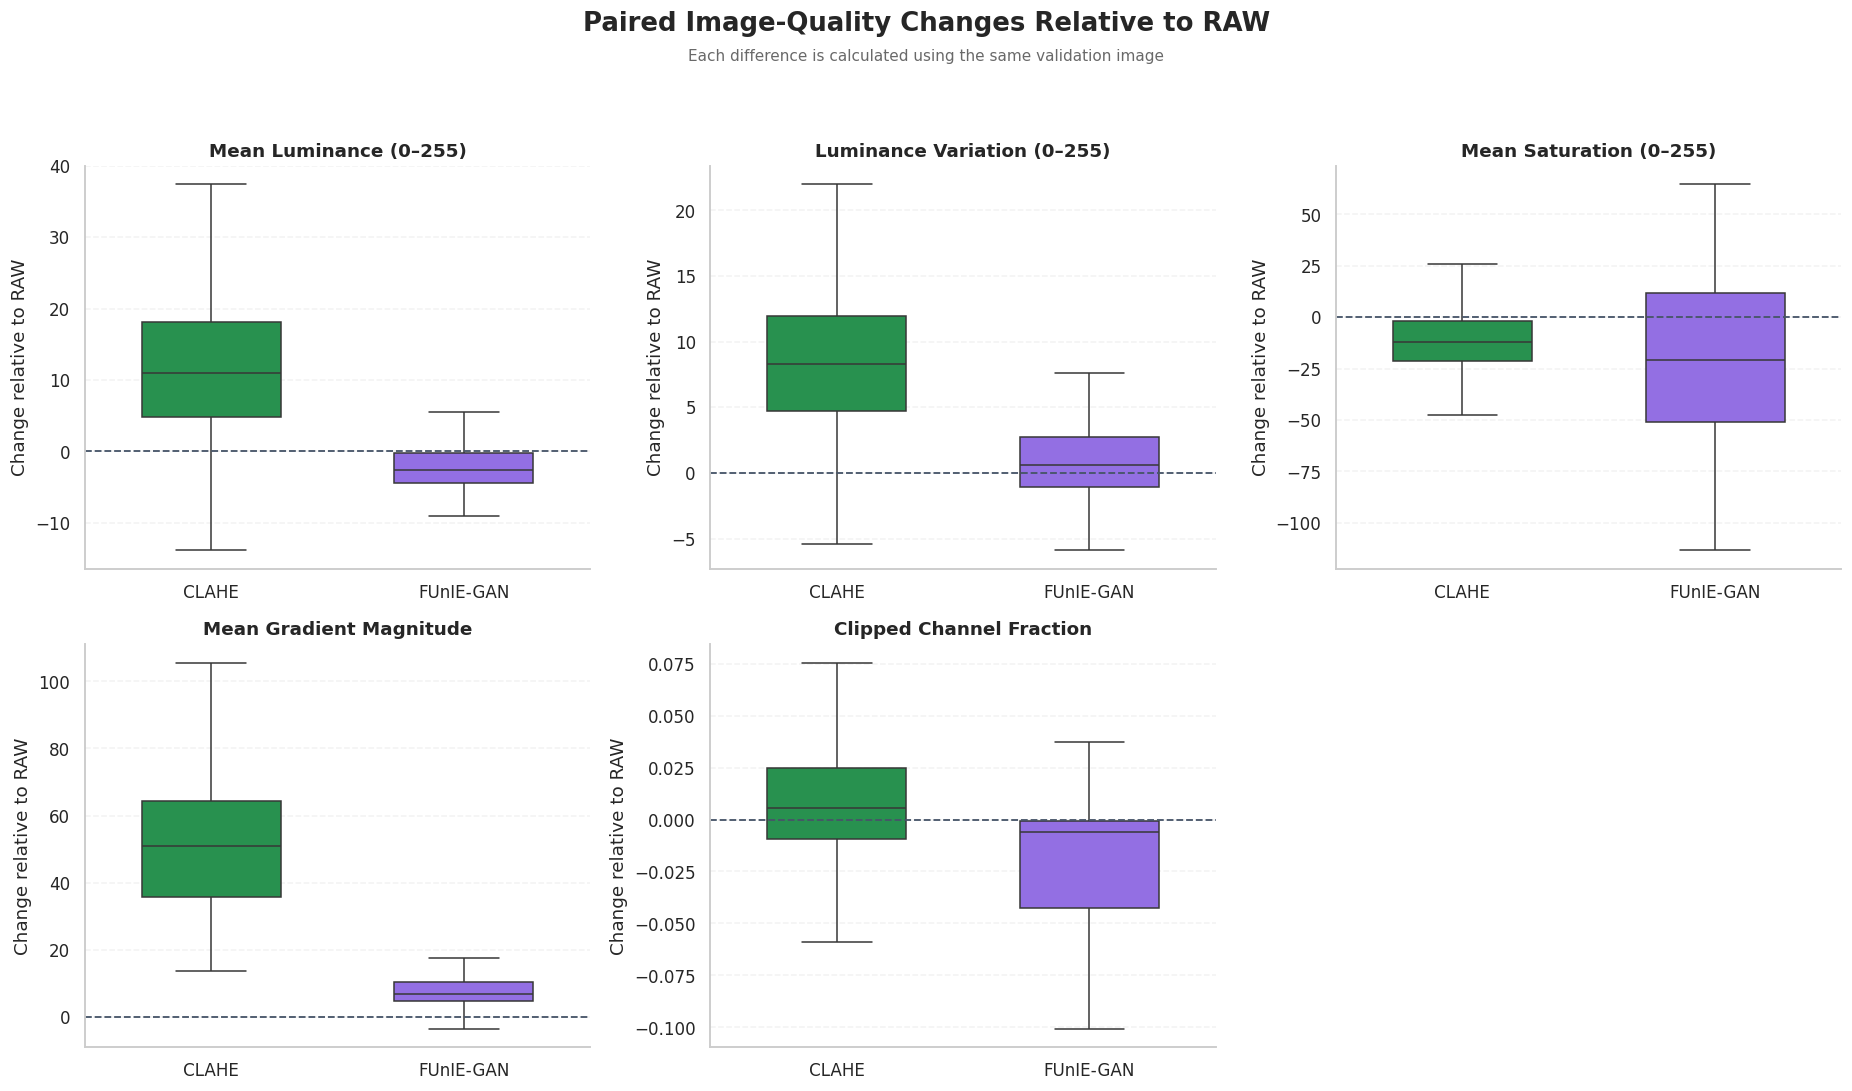

Tables saved to: /content/drive/MyDrive/Underwater_Research/results/tables/notebook_03
Figures saved to: /content/drive/MyDrive/Underwater_Research/results/figures/notebook_03


In [12]:
def quality_metrics(rgb):
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)

    return {
        "luminance_mean": float(lab[:, :, 0].mean()),
        "luminance_std": float(lab[:, :, 0].std()),
        "saturation_mean": float(hsv[:, :, 1].mean()),
        "gradient_mean": float(np.hypot(gx, gy).mean()),
        "clipped_fraction": float(
            np.logical_or(rgb <= 2, rgb >= 253).mean()
        )
    }


# 10.1 — Calculate image-quality metrics

metric_names = [
    "luminance_mean",
    "luminance_std",
    "saturation_mean",
    "gradient_mean",
    "clipped_fraction"
]

method_order = ["raw", "clahe", "funie_gan"]

method_labels = {
    "raw": "RAW",
    "clahe": "CLAHE",
    "funie_gan": "FUnIE-GAN"
}

method_colors = {
    "raw": "#64748B",
    "clahe": "#16A34A",
    "funie_gan": "#8B5CF6"
}

metric_titles = {
    "luminance_mean": "Mean Luminance (0–255)",
    "luminance_std": "Luminance Variation (0–255)",
    "saturation_mean": "Mean Saturation (0–255)",
    "gradient_mean": "Mean Gradient Magnitude",
    "clipped_fraction": "Clipped Channel Fraction"
}

quality_rows = []

for i in range(len(DATASETS["val"])):
    stem = image_stem("val", i)

    images = {
        "raw": raw_rgb("val", i),
        "clahe": load_enhanced("val", i, "clahe"),
        "funie_gan": load_enhanced("val", i, "funie_gan")
    }

    for method, image in images.items():
        quality_rows.append({
            "split": "val",
            "stem": stem,
            "method": method,
            **quality_metrics(image)
        })

quality_df = pd.DataFrame(quality_rows)

expected_rows = len(DATASETS["val"]) * len(method_order)

assert len(quality_df) == expected_rows
assert quality_df["stem"].nunique() == 214
assert quality_df[metric_names].notna().all().all()
assert set(quality_df["method"]) == set(method_order)

quality_df.to_csv(
    TABLES / "enhancement_metrics.csv",
    index=False
)

print(f"Image-quality measurements: {len(quality_df):,}")
print(f"Unique validation images: {quality_df['stem'].nunique()}")
print("Methods:", ", ".join(method_labels.values()))


# 10.2 — Summary statistics

quality_summary = (
    quality_df
    .groupby("method")[metric_names]
    .agg(["mean", "std", "median"])
    .reindex(method_order)
    .round(3)
)

quality_summary.index = [
    method_labels[method] for method in quality_summary.index
]

print("\nImage-Quality Summary Statistics")
display(quality_summary)

quality_summary.to_csv(
    TABLES / "image_quality_summary.csv"
)


# 10.3 — Image-quality distributions

fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 10)
)

for ax, metric in zip(axes.flat, metric_names):

    sns.violinplot(
        data=quality_df,
        x="method",
        y=metric,
        hue="method",
        order=method_order,
        hue_order=method_order,
        palette=method_colors,
        inner="quartile",
        cut=0,
        density_norm="width",
        legend=False,
        linewidth=1.1,
        ax=ax
    )

    ax.set_title(
        metric_titles[metric],
        fontsize=12,
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_xticks(range(len(method_order)))
    ax.set_xticklabels(
        [method_labels[m] for m in method_order],
        fontsize=10
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    sns.despine(ax=ax)

axes.flat[-1].axis("off")

fig.suptitle(
    "Image-Quality Distributions Across Enhancement Methods",
    fontsize=17,
    fontweight="bold",
    y=0.99
)

fig.text(
    0.5,
    0.945,
    "Paired validation images (n = 214) | "
    "Median and quartiles shown inside each violin",
    ha="center",
    fontsize=10,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0, 1, 0.93])

fig.savefig(
    FIGURES / "image_quality_distributions.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# 10.4 — Paired changes relative to RAW

paired = quality_df.pivot(
    index="stem",
    columns="method",
    values=metric_names
)

assert len(paired) == 214
assert not paired.isna().any().any()

change_rows = []
paired_change_rows = []

for metric in metric_names:
    for method in ["clahe", "funie_gan"]:

        difference = (
            paired[(metric, method)]
            - paired[(metric, "raw")]
        )

        change_rows.append({
            "metric": metric,
            "method": method,
            "mean_change": float(difference.mean()),
            "median_change": float(difference.median()),
            "std_change": float(difference.std()),
            "positive_fraction": float((difference > 0).mean())
        })

        for stem, value in difference.items():
            paired_change_rows.append({
                "stem": stem,
                "metric": metric,
                "method": method,
                "change_from_raw": float(value)
            })

change_df = pd.DataFrame(change_rows)
paired_change_df = pd.DataFrame(paired_change_rows)

change_df.to_csv(
    TABLES / "paired_metric_changes.csv",
    index=False
)

paired_change_df.to_csv(
    TABLES / "paired_metric_changes_per_image.csv",
    index=False
)

print("\nPaired Image-Quality Changes Relative to RAW")
display(change_df.round(4))


# 10.5 — Visualize paired changes

fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 10)
)

for ax, metric in zip(axes.flat, metric_names):

    subset = paired_change_df[
        paired_change_df["metric"] == metric
    ]

    sns.boxplot(
        data=subset,
        x="method",
        y="change_from_raw",
        hue="method",
        order=["clahe", "funie_gan"],
        hue_order=["clahe", "funie_gan"],
        palette=method_colors,
        legend=False,
        showfliers=False,
        width=0.55,
        ax=ax
    )

    ax.axhline(
        0,
        color="#475569",
        linestyle="--",
        linewidth=1.2
    )

    ax.set_title(
        metric_titles[metric],
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel("")
    ax.set_ylabel("Change relative to RAW")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["CLAHE", "FUnIE-GAN"])

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    sns.despine(ax=ax)

axes.flat[-1].axis("off")

fig.suptitle(
    "Paired Image-Quality Changes Relative to RAW",
    fontsize=17,
    fontweight="bold",
    y=0.99
)

fig.text(
    0.5,
    0.945,
    "Each difference is calculated using the same validation image",
    ha="center",
    fontsize=10,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0, 1, 0.93])

fig.savefig(
    FIGURES / "paired_quality_changes.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Tables saved to:", TABLES)
print("Figures saved to:", FIGURES)



### 10.6 Quantitative Results and Research Interpretation

To evaluate how underwater image enhancement affects image characteristics, I compared **RAW, CLAHE, and FUnIE-GAN** using five quantitative image-quality metrics across the **214 validation images**. Each enhanced image was compared directly with its corresponding RAW image, allowing me to examine changes caused by enhancement rather than differences between images.

The analysis considers luminance, luminance variation, saturation, gradient magnitude, and pixel clipping. These metrics describe different aspects of image appearance, but none independently establishes whether an image is better suited for semantic segmentation.

### 10.6.1 Summary of Quantitative Findings

| Image-quality metric | RAW baseline | CLAHE change | FUnIE-GAN change |
|---|---:|---:|---:|
| Mean luminance | 108.68 | +10.89 | -2.21 |
| Luminance variation | 43.68 | +8.46 | +0.91 |
| Mean saturation | 145.41 | -12.75 | -20.05 |
| Mean gradient magnitude | 61.18 | +49.78 | +7.51 |
| Clipped channel fraction | 0.0384 | +0.0013 | -0.0338 |

**Note:** Changes represent the mean paired difference relative to the original RAW images. Positive values indicate an increase, while negative values indicate a decrease.

### 10.6.2 Brightness and Luminance

CLAHE increased mean luminance by **10.89 units**, with **87.4% of validation images** becoming brighter. This suggests that CLAHE generally increased the visibility of darker image regions.

In contrast, FUnIE-GAN decreased mean luminance by **2.21 units**, with only **22.0% of images** showing increased brightness. This indicates that FUnIE-GAN did not consistently brighten the underwater images.

These findings suggest that the two enhancement approaches modify illumination differently. CLAHE generally increases brightness, whereas FUnIE-GAN produces more varied brightness adjustments.

However, increased brightness does not necessarily imply better image quality. Excessive brightening may reduce local detail or amplify unwanted visual artifacts.

### 10.6.3 Contrast and Luminance Variation

CLAHE increased luminance standard deviation by **8.46 units**, with **94.4% of images** showing increased variation.

This is consistent with CLAHE's objective of improving local contrast. The increased variation suggests greater separation between darker and brighter image regions.

FUnIE-GAN produced a smaller average increase of **0.91 units**, with **59.8% of images** showing increased luminance variation.

The results indicate that **CLAHE produces a substantially stronger contrast-related response than FUnIE-GAN** under the selected experimental configuration.

However, luminance standard deviation measures global intensity variation rather than local contrast directly. Therefore, these findings should be interpreted alongside qualitative image comparisons.

### 10.6.4 Color Saturation

Both enhancement methods reduced average color saturation.

CLAHE decreased saturation by **12.75 units**, while FUnIE-GAN produced a larger decrease of **20.05 units**.

Only **18.2% of CLAHE images** and **34.1% of FUnIE-GAN images** showed increased saturation.

These findings suggest that both methods generally reduced color intensity, although FUnIE-GAN produced the larger average reduction.

Reduced saturation is not necessarily undesirable in underwater imagery. Underwater images frequently exhibit strong color casts caused by wavelength-dependent light absorption.

However, lower saturation alone does not demonstrate improved color accuracy. Without reference images representing true scene colors, I cannot determine whether these changes constitute successful color correction.

### 10.6.5 Gradient Magnitude and Image Detail

The largest difference between the methods appeared in gradient magnitude.

CLAHE increased mean gradient magnitude by **49.78 units**, with **100% of validation images** showing an increase.

FUnIE-GAN increased gradient magnitude by **7.51 units**, with **93.9% of images** showing an increase.

Gradient magnitude measures the strength of local intensity changes and can indicate more prominent edges and image structures.

These results suggest that CLAHE substantially strengthens local intensity transitions, potentially making object boundaries and textures more visually pronounced.

This observation is particularly relevant to underwater robotic segmentation, where distinguishing object boundaries can be challenging.

However, **stronger gradients do not necessarily indicate better object boundaries**. Enhancement may also amplify image noise, suspended-particle interference, or irrelevant textures.

Therefore, I cannot conclude that the increased gradient magnitude will improve CNN segmentation performance without evaluating the frozen U-Net in Notebook 04.

### 10.6.6 Pixel Clipping and Potential Detail Loss

The original RAW images had a mean clipped channel fraction of **0.0384**, equivalent to approximately **3.84%** of channel values near the lower or upper intensity limits.

CLAHE increased this fraction by **0.0013**, with **67.3% of images** showing increased clipping.

FUnIE-GAN decreased the clipped fraction by **0.0338**, with only **4.7% of images** showing increased clipping.

These results suggest that FUnIE-GAN substantially reduced the occurrence of near-extreme channel values, while CLAHE produced a small average increase.

This may indicate that FUnIE-GAN compresses extreme intensity values or redistributes image intensities away from the limits.

However, fewer clipped pixels do not necessarily imply greater preservation of original scene information. A transformation can reduce clipping without recovering details already lost during image capture.

### 10.6.7 Overall Comparison of Enhancement Methods

The quantitative results reveal distinct enhancement behaviors.

**CLAHE** produced:
- Higher average brightness.
- Substantially increased luminance variation.
- Stronger local intensity gradients.
- Reduced average saturation.
- A small increase in near-extreme pixel values.

**FUnIE-GAN** produced:
- A small reduction in average brightness.
- A modest increase in luminance variation.
- Reduced average saturation.
- A smaller increase in gradient magnitude.
- A substantial reduction in near-extreme pixel values.

These differences suggest that CLAHE emphasizes contrast and local intensity transitions, whereas FUnIE-GAN applies a comparatively restrained transformation to the measured contrast and gradient characteristics while reducing extreme channel values.

Importantly, these metrics describe changes in image statistics rather than perceptual quality or semantic understanding.

### 10.6.8 Implications for Plant and Robot Segmentation

The results are especially relevant to the **plant and robot classes**, which presented substantial difficulties in Notebook 02.

The baseline U-Net achieved **0% IoU for plants** and approximately **7.05% IoU for robots** on the validation set.

For plants, stronger local contrast could potentially improve the visibility of fine vegetation structures. However, CLAHE might also amplify reef textures, making visually similar classes more difficult to distinguish.

For robots, increased gradient magnitude could make object boundaries more prominent. Nevertheless, stronger boundaries alone may not resolve confusion between robots and other underwater objects.

FUnIE-GAN's reduction in extreme channel values may alter the appearance of poorly illuminated regions, but its effects on class-specific features remain uncertain.

These are **hypotheses rather than demonstrated segmentation improvements**.

The plant- and robot-focused analysis in Section 12 will examine enhancement behavior within annotated class regions. Notebook 04 will then determine whether these changes improve or degrade segmentation predictions.

### 10.6.9 Limitations of the Quantitative Analysis

Several limitations must be considered when interpreting these findings.

First, the selected metrics are primarily descriptive and do not directly measure perceptual image quality.

Second, increased gradient magnitude may reflect amplified noise rather than useful structural information.

Third, color saturation and luminance changes cannot establish color accuracy without suitable reference images.

Fourth, the analysis uses the validation dataset and does not establish how enhancement affects segmentation on unseen test images.

Finally, these metrics are not equally informative for every underwater scene. Images containing different illumination conditions, object sizes, and background structures may respond differently to the same enhancement method.

### 10.7 Section Conclusion

The quantitative analysis demonstrates that **CLAHE and FUnIE-GAN produce meaningfully different changes in underwater image characteristics**.

CLAHE consistently increases contrast-related measurements and gradient magnitude, while FUnIE-GAN produces smaller changes in these measurements and substantially reduces near-extreme channel values.

Neither method can be declared superior based on these results alone.

**The central research question remains whether these image-level changes translate into better semantic segmentation when evaluated using the same frozen U-Net.**

The next analyses will examine processing efficiency, plant and robot regions, and potential enhancement artifacts before the final segmentation evaluation in Notebook 04.


## 11. Computational efficiency

I report processing latency as a practical characteristic of the enhancement pipelines. Timings are **wall-clock measurements** on the active Colab hardware, including image transformation and device transfers but excluding disk writing. GPU operations are synchronized. These are descriptive measurements, not hardware-independent benchmarks. For rigorous inference benchmarking, additional warm-up and repeated measurements would be needed.

,count,mean,median,std,min,max
method,,,,,,
clahe,214,2.20,2.07,0.39,1.82,4.51
funie_gan,214,9.08,8.98,1.10,8.53,24.23


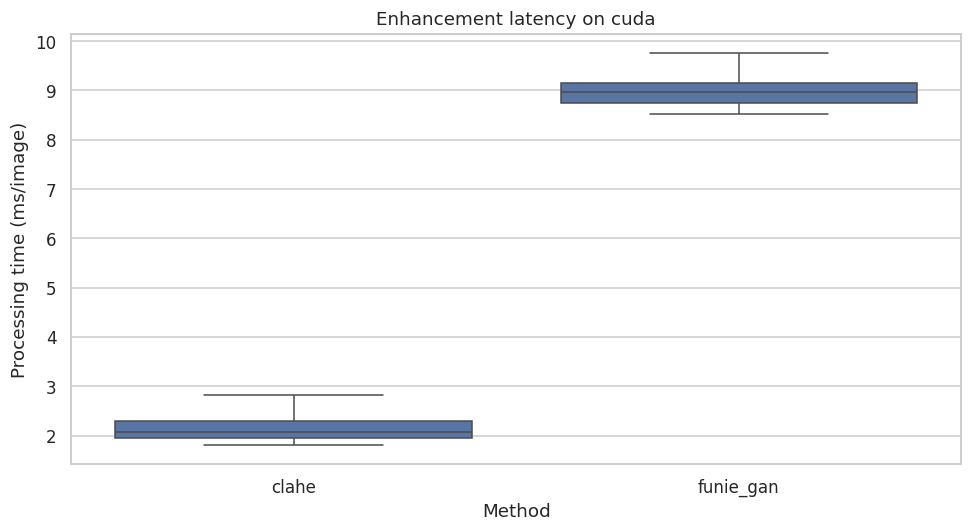

In [13]:
timing_df=val_outputs[['split','stem','method','processing_ms']].copy()
timing_df.to_csv(TABLES/'processing_times.csv',index=False)
summary_timing=timing_df.groupby('method')['processing_ms'].agg(['count','mean','median','std','min','max']).round(2)
display(summary_timing)
fig,ax=plt.subplots(figsize=(9,5))
sns.boxplot(data=timing_df,x='method',y='processing_ms',showfliers=False,ax=ax)
ax.set(title=f'Enhancement latency on {DEVICE}',xlabel='Method',ylabel='Processing time (ms/image)')
plt.tight_layout()
fig.savefig(FIGURES/'processing_time_comparison.png',bbox_inches='tight')
plt.show()

## 12. Plant and robot focused enhancement analysis

Notebook 02 identified two important weaknesses: **plant was never predicted on validation**, and **robot achieved 7.05% IoU**. I therefore inspect enhanced images containing these annotated categories. I select validation examples by the number of ground-truth plant or robot pixels and display the **same RAW / CLAHE / FUnIE-GAN images**, with annotation-guided close-ups.

I also compute descriptive changes in luminance and gradient magnitude **inside the annotated target regions**. These measurements characterize image appearance only; they do **not** measure recognition, segmentation recall, or IoU. The original masks are read solely for region selection and remain unchanged.

In [15]:
def region_metrics(rgb, mask):
    if not mask.any():
        return {'region_luminance':np.nan,'region_gradient':np.nan}
    gray=cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)
    gx=cv2.Sobel(gray,cv2.CV_32F,1,0,ksize=3)
    gy=cv2.Sobel(gray,cv2.CV_32F,0,1,ksize=3)
    return {'region_luminance':float(gray[mask].mean()),
            'region_gradient':float(np.hypot(gx,gy)[mask].mean())}

region_rows=[]
for class_name in ['plant','robot']:
    class_id=CLASS_NAMES.index(class_name)
    candidates=[]
    for i in range(len(DATASETS['val'])):
        count=int((get_mask('val',i)==class_id).sum())
        if count>0:
            candidates.append((i,count))
    candidates.sort(key=lambda pair:pair[1],reverse=True)
    print(f'{class_name}: {len(candidates)} annotated validation images; showing top {min(4,len(candidates))}')
    selected=candidates[:4]
    if not selected:
        continue
    fig,axes=plt.subplots(len(selected),4,figsize=(16,4*len(selected)),squeeze=False)
    for row,(i,count) in enumerate(selected):
        gt=get_mask('val',i)
        region=gt==class_id
        ys,xs=np.where(region)
        y0,y1=max(0,int(ys.min())-12),min(256,int(ys.max())+13)
        x0,x1=max(0,int(xs.min())-12),min(256,int(xs.max())+13)
        images=[raw_rgb('val',i),load_enhanced('val',i,'clahe'),load_enhanced('val',i,'funie_gan')]
        for method,image in zip(['raw','clahe','funie_gan'],images):
            region_rows.append({'class':class_name,'stem':image_stem('val',i),'method':method,
                                'region_pixels':count,**region_metrics(image,region)})
        for col,image in enumerate(images):
            axes[row,col].imshow(image)
            axes[row,col].axis('off')
            axes[row,col].set_title(['RAW','CLAHE','FUnIE-GAN'][col] if row==0 else '')
        axes[row,3].imshow(images[0][y0:y1,x0:x1])
        axes[row,3].contour(region[y0:y1,x0:x1].astype(float),levels=[0.5],colors='yellow',linewidths=1)
        axes[row,3].axis('off')
        axes[row,3].set_title('RAW crop + annotation' if row==0 else '')
        axes[row,0].set_ylabel(f'{image_stem("val",i)} | {count:,} pixels')
    fig.suptitle(f'{class_name.title()} - enhancement and annotated regions',fontsize=14,fontweight='bold')
    plt.tight_layout(rect=(0,0,1,0.96))
    fig.savefig(FIGURES/f'{class_name}_focused_enhancement.png',bbox_inches='tight')
    plt.show()
region_df=pd.DataFrame(region_rows)
assert set(region_df['class'])=={'plant','robot'}, 'Expected both annotated classes in validation.'
region_df.to_csv(TABLES/'plant_robot_region_metrics.csv',index=False)
display(region_df.groupby(['class','method'])[['region_luminance','region_gradient']].mean().round(2))

Output hidden; open in https://colab.research.google.com to view.

## 13. Enhancement behavior and limitations

Image-quality descriptors are **not interchangeable with task accuracy**. CLAHE can exaggerate local contrast and noise, while FUnIE-GAN can introduce color shifts or synthetic-looking textures. I examine the distribution of luminance, color, and clipping as evidence of changed appearance, but these statistics alone cannot establish improved underwater visibility or scientific restoration quality. I also inspect per-image RGB histograms for possible saturation and color-distribution shifts.

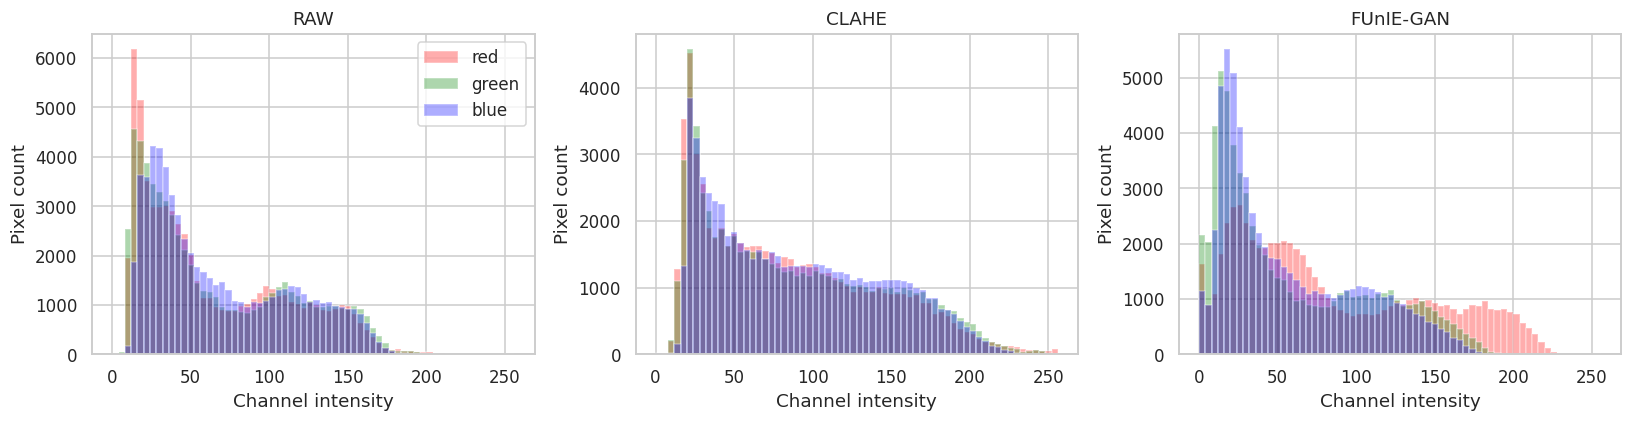

Interpretation note: higher saturation or contrast is not proof of improved segmentation.


In [16]:
idx=int(selection_indices[0])
images=[raw_rgb('val',idx),load_enhanced('val',idx,'clahe'),load_enhanced('val',idx,'funie_gan')]
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,method,image in zip(axes,['RAW','CLAHE','FUnIE-GAN'],images):
    for channel,color in enumerate(['red','green','blue']):
        ax.hist(image[:,:,channel].ravel(),bins=64,range=(0,256),alpha=0.32,color=color,label=color)
    ax.set(title=method,xlabel='Channel intensity',ylabel='Pixel count')
axes[0].legend()
plt.tight_layout()
fig.savefig(FIGURES/'color_histograms.png',bbox_inches='tight')
plt.show()
print('Interpretation note: higher saturation or contrast is not proof of improved segmentation.')

## 14. Output verification and reproducibility

Only after locking the enhancement configuration and reviewing validation outputs do I generate **test-set enhancement files**. I verify that every official test stem has exactly one CLAHE and one FUnIE-GAN PNG, with the same dimensions as RAW. I write a persistent enhancement manifest with output paths and SHA256 hashes. **The test set is processed but not inspected for parameter selection or U-Net performance in this notebook.**

In [17]:
assert json.loads(config_file.read_text()) == LOCKED_CONFIG
assert len(val_outputs)==428
test_outputs=generate_split('test')
assert len(test_outputs)==220
all_outputs=pd.concat([val_outputs,test_outputs],ignore_index=True)
assert not all_outputs.duplicated(['split','stem','method']).any()
for split in ['val','test']:
    expected=set(df.loc[df['split']==split,'stem'].astype(str))
    for method in ['clahe','funie_gan']:
        subset=all_outputs[(all_outputs['split']==split)&(all_outputs['method']==method)]
        assert set(subset['stem'])==expected, f'Incomplete {method} {split} outputs'
        assert len(subset)==len(expected)
        assert all(Path(p).is_file() for p in subset['output_path'])
        assert (subset['height'].eq(256)&subset['width'].eq(256)).all()
all_outputs.to_csv(TABLES/'enhancement_manifest.csv',index=False)
assert len(all_outputs)==648
print('Verified 428 validation outputs + 220 official test outputs = 648 enhanced PNGs.')
print('Manifest:',TABLES/'enhancement_manifest.csv')
print('Locked configuration:',config_file)
print('FUnIE-GAN SHA256:',funie_sha)
display(all_outputs.groupby(['split','method']).size().rename('images').reset_index())

/tmp/ipykernel_498/3498677958.py:27: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(enhanced,'RGB').save(output_path)


test: 40/110 images processed
test: 80/110 images processed
test: 110/110 images processed
Verified 428 validation outputs + 220 official test outputs = 648 enhanced PNGs.
Manifest: /content/drive/MyDrive/Underwater_Research/results/tables/notebook_03/enhancement_manifest.csv
Locked configuration: /content/drive/MyDrive/Underwater_Research/results/tables/notebook_03/enhancement_config.json
FUnIE-GAN SHA256: e4fcb50e03868f1683c244b1c125def30df335ec43d9bb001b8700c03b8f2bd6


,split,method,images
0,test,clahe,110
1,test,funie_gan,110
2,val,clahe,214
3,val,funie_gan,214



## 15. Discussion, Conclusion, and Research Handoff

### 15.1 Overview of the Research

In this notebook, I investigated the effects of two underwater image enhancement techniques, **Contrast Limited Adaptive Histogram Equalization (CLAHE)** and **Fast Underwater Image Enhancement GAN (FUnIE-GAN)**, on images from the **SUIM dataset**.

The purpose was to understand how enhancement changes underwater image characteristics before evaluating whether those changes benefit CNN-based semantic segmentation.

I compared the original **RAW images** with their CLAHE-enhanced and FUnIE-GAN-enhanced versions using:

- Qualitative image comparisons.
- Quantitative image-quality measurements.
- Computational efficiency analysis.
- Targeted examination of plant and robot regions.
- Output-integrity and reproducibility checks.

The experiment preserved the original dataset partitions, image identities, spatial dimensions, and segmentation ground-truth masks.

**The central distinction throughout this notebook is that improving the visual appearance of an image does not necessarily improve the ability of a CNN to segment objects within it.**

### 15.2 Discussion of Quantitative Findings

The quantitative analysis was conducted using **214 validation images**, with each enhanced image compared directly against its original RAW counterpart.

The results revealed distinct enhancement behaviors.

| Metric | RAW mean | CLAHE change | FUnIE-GAN change |
|---|---:|---:|---:|
| Mean luminance | 108.68 | +10.89 | -2.21 |
| Luminance variation | 43.68 | +8.46 | +0.91 |
| Mean saturation | 145.41 | -12.75 | -20.05 |
| Mean gradient magnitude | 61.18 | +49.78 | +7.51 |
| Clipped channel fraction | 0.0384 | +0.0013 | -0.0338 |

*Changes represent mean paired differences relative to RAW images.*

#### CLAHE

CLAHE produced substantial increases in luminance variation and gradient magnitude. Luminance variation increased in **94.4% of validation images**, while gradient magnitude increased in **100% of images**. These findings are consistent with CLAHE's purpose of strengthening local contrast. The increased gradient magnitude suggests stronger intensity transitions, which may make certain object boundaries and textures more prominent. However, stronger gradients may also reflect amplified noise or irrelevant background details.

**Therefore, increased contrast and gradient magnitude should not automatically be interpreted as improved segmentation-relevant information.**

#### FUnIE-GAN

FUnIE-GAN produced smaller average changes in luminance variation and gradient magnitude than CLAHE. Its most notable quantitative effect was a reduction in the clipped channel fraction by **0.0338**. This indicates that fewer channel values were concentrated near the lower and upper intensity limits after enhancement. However, reducing near-extreme pixel values does not necessarily recover details lost during image acquisition. FUnIE-GAN also reduced average saturation, demonstrating that learned enhancement does not necessarily produce brighter or more saturated images.

#### Comparison of the Methods

The findings suggest that **CLAHE emphasizes contrast-related changes and local intensity transitions**, whereas **FUnIE-GAN produces smaller changes in these measurements while substantially reducing near-extreme channel values**.

Both methods reduced average color saturation.

These differences demonstrate that enhancement techniques can modify underwater images in substantially different ways.

**Neither method can be declared superior based on descriptive image-quality measurements alone.**

### 15.3 Implications for Plant and Robot Segmentation

The plant and robot classes are particularly important because they presented substantial difficulties during the baseline U-Net experiment in Notebook 02.

The baseline validation results were:

| Class | Validation IoU |
|---|---:|
| Plant | **0.00%** |
| Robot | **7.05%** |

The model did not correctly identify plant pixels and achieved limited segmentation performance for robotic objects.

These findings motivated the targeted enhancement analysis conducted in this notebook.

For **plant regions**, stronger local contrast could potentially make vegetation structures more distinguishable. However, it could also amplify reef textures and other visually similar background features.

For **robot regions**, stronger gradients may make some object boundaries more prominent. Nevertheless, more visible boundaries do not guarantee that a CNN will classify those pixels correctly.

FUnIE-GAN may also change the appearance of plant and robot regions through its learned image transformation.

These changes could improve, degrade, or have little effect on the predictions of a model trained on RAW imagery.

**The potential benefits remain hypotheses until the enhancement methods are evaluated through semantic segmentation.**

### 15.4 Interpretation of Computational Efficiency

Computational efficiency is an important consideration for underwater robotic systems, particularly when image processing must occur before segmentation. CLAHE is a deterministic image-processing technique, while FUnIE-GAN requires neural-network inference. The processing-time measurements in Section 11 provide a comparison of their computational requirements under the experimental environment. However, these measurements are influenced by factors such as hardware, implementation, image size, and execution conditions.

**The recorded processing times should therefore be interpreted as experimental measurements rather than guaranteed real-time performance on underwater robotic hardware.**

A method that improves image appearance may still be unsuitable for a time-sensitive robotic application if its computational cost is too high. The final assessment of practical usefulness must consider both segmentation performance and processing overhead.

### 15.5 Experimental Reproducibility and Verification

The experiment followed the locked SUIM dataset partitions established in Notebook 01.

| Dataset partition | Images |
|---|---:|
| Training | 1,204 |
| Validation | 214 |
| Test | 110 |
| **Total** | **1,528** |

The original segmentation masks remained unchanged, and all enhanced images retained the required **256 × 256 RGB** format.

CLAHE parameters and the pretrained FUnIE-GAN configuration were fixed before processing the official test images.

Section 14 successfully verified the generated enhancement outputs.

| Dataset partition | CLAHE | FUnIE-GAN | Total |
|---|---:|---:|---:|
| Validation | 214 | 214 | 428 |
| Test | 110 | 110 | 220 |
| **Total** | **324** | **324** | **648** |

**All 648 enhanced images passed the notebook's programmed output-integrity checks.**

The enhancement configuration, image manifest, quantitative measurements, and generated figures were saved in the `Underwater_Research` directory.

This provides a reproducible foundation for the controlled segmentation evaluation.

### 15.6 Research Limitations

Several limitations must be acknowledged.

**First, the absence of paired clean reference images** prevents direct measurement of restoration accuracy or true color recovery.

**Second, descriptive image-quality metrics do not directly measure semantic segmentation performance.** Increased contrast, saturation, or gradient magnitude does not necessarily correspond to better object recognition.

**Third, enhancement may introduce unwanted visual changes.** These include amplified noise, altered textures, or changes to features that the segmentation model learned from RAW images.

**Fourth, the pretrained FUnIE-GAN model may experience domain differences** between its original training data and SUIM underwater imagery.

**Fifth, computational efficiency measurements depend on the experimental hardware and implementation.** They cannot directly establish performance on deployed underwater robotic systems.

**Finally, the quantitative enhancement analysis uses validation images.** It does not establish whether enhancement improves segmentation on unseen test images. These limitations reinforce the need for a controlled downstream evaluation.

### 15.7 Next Stage: Notebook 04 - Controlled Segmentation Evaluation

Notebook 04 will investigate the main research question:

**Does underwater image enhancement improve, degrade, or have mixed effects on the semantic segmentation performance of an existing CNN model?**

I will use the **same frozen U-Net checkpoint from Notebook 02**, selected at **epoch 112**, to evaluate three input conditions.

| Experimental condition | Input images | Segmentation model |
|---|---|---|
| Baseline | RAW | Frozen RAW-trained U-Net |
| Experiment 1 | CLAHE | Same frozen RAW-trained U-Net |
| Experiment 2 | FUnIE-GAN | Same frozen RAW-trained U-Net |

All three conditions will use the **same 110 official test images** and their corresponding original ground-truth segmentation masks. The U-Net architecture, trained weights, and evaluation procedures will remain unchanged.

**The model will not be retrained or fine-tuned for either enhancement method.**

This design isolates the effect of changing the input images on the predictions of the existing RAW-trained model.

The evaluation will focus on:

1. **Mean Intersection over Union (mIoU)** for overall segmentation performance.
2. **Pixel accuracy** for the proportion of correctly classified pixels.
3. **Per-class IoU** to examine changes across the eight SUIM categories.
4. **Plant and robot performance** to investigate the classes that presented the greatest baseline difficulties.
5. **Class confusion matrices** to identify changes in prediction errors.
6. **Qualitative segmentation comparisons** to examine differences in predicted masks.

No enhancement parameters or model hyperparameters will be adjusted based on the official test results.

**This experiment will determine whether the image-level changes observed in Notebook 03 translate into measurable differences in segmentation accuracy.**

### 15.8 Final Stage: Notebook 05 - Critical Analysis and Research Conclusions

Notebook 05 will synthesize the findings from the baseline segmentation experiment, image enhancement analysis, and controlled segmentation evaluation.

The final analysis will examine:

- Whether CLAHE or FUnIE-GAN improves overall segmentation accuracy.
- Whether enhancement affects plant and robot segmentation differently from other classes.
- Whether improvements in image-quality measurements correspond to improvements in segmentation performance.
- Whether any segmentation benefits justify the additional computational cost.
- What the findings suggest about the usefulness and limitations of image enhancement for underwater robotic perception.

The discussion will distinguish between **visual image quality, task-level segmentation accuracy, and practical computational requirements**. It will also identify limitations and opportunities for future research, including the potential evaluation of models trained specifically on enhanced imagery.

### 15.9 Final Conclusion

This notebook established and evaluated two reproducible underwater image enhancement pipelines using **CLAHE and pretrained FUnIE-GAN**. The results demonstrate that the methods produce different changes in brightness, luminance variation, color saturation, gradient magnitude, and pixel clipping.

**CLAHE consistently strengthened contrast-related measurements and intensity gradients, while FUnIE-GAN substantially reduced near-extreme channel values.**

However, these findings do not establish which method is more beneficial for underwater robotic segmentation. The successful verification of **648 enhanced images** confirms that the required validation and test outputs have been prepared for the next stage of the research. The most important conclusion is that **visual enhancement and semantic segmentation improvement are not necessarily equivalent**. By preserving the original dataset partitions, segmentation masks, enhancement configurations, and output records, this notebook provides a controlled foundation for evaluating enhancement effects on CNN predictions.

**Notebook 04 will measure those effects using the same frozen U-Net across RAW, CLAHE, and FUnIE-GAN inputs. Notebook 05 will integrate the experimental findings into the final research discussion and conclusions.**
